<a href="https://colab.research.google.com/github/Saransh-Basu-01/50-Ml-Projects-to-understand-LLMs/blob/main/Project_22_Evaluating_models_with_hellaswag.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
import numpy as np
import matplotlib.pyplot as plt

from tqdm import tqdm
from datasets import load_dataset

from statsmodels.stats.contingency_tables import mcnemar

# pytorch-related libraries
import torch
import torch.nn as nn
import torch.nn.functional as F

# libraries to import models
from transformers import AutoModelForCausalLM, AutoTokenizer
from transformers import RobertaTokenizer, RobertaForMaskedLM

# Part_1:Import and Compare GPT-2 and Roberta Model

## Task_1:
- Import four models: GPT-2-small, GPT-2-large, RoBERTa-base,
and RoBERTa-large. The two GPT-2 variants use the same tok
enizer, and the two RoBERTa variants use the same tokenizer. Make
sure all models and tokenizers have interpretable variable names,
e.g., gpt2_s and tokenizerG.
Switch the models to evaluation mode and move them to the
GPU.
Write code to create the table below (Xfmr is “transformer”;
the number of transformer layers)

In [2]:
device=torch.device("cuda" if torch.cuda.is_available() else "cpu")
device

device(type='cuda')

In [3]:
tokenizerG = AutoTokenizer.from_pretrained('gpt2')
gpt2_s = AutoModelForCausalLM.from_pretrained('gpt2').to(device)
gpt2_l = AutoModelForCausalLM.from_pretrained('gpt2-large').to(device)
gpt2_s.eval()
gpt2_l.eval()

config.json:   0%|          | 0.00/665 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/26.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/1.04M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  548MB            

... (5 outputs left out)

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/436 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/124 [00:00<?, ?B/s]

GPT2LMHeadModel(
  (transformer): GPT2Model(
    (wte): Embedding(50257, 1280)
    (wpe): Embedding(1024, 1280)
    (drop): Dropout(p=0.1, inplace=False)
    (h): ModuleList(
      (0-35): 36 x GPT2Block(
        (ln_1): LayerNorm((1280,), eps=1e-05, elementwise_affine=True)
        (attn): GPT2Attention(
          (c_attn): Conv1D(nf=3840, nx=1280)
          (c_proj): Conv1D(nf=1280, nx=1280)
          (attn_dropout): Dropout(p=0.1, inplace=False)
          (resid_dropout): Dropout(p=0.1, inplace=False)
        )
        (ln_2): LayerNorm((1280,), eps=1e-05, elementwise_affine=True)
        (mlp): GPT2MLP(
          (c_fc): Conv1D(nf=5120, nx=1280)
          (c_proj): Conv1D(nf=1280, nx=5120)
          (act): NewGELUActivation()
          (dropout): Dropout(p=0.1, inplace=False)
        )
      )
    )
    (ln_f): LayerNorm((1280,), eps=1e-05, elementwise_affine=True)
  )
  (lm_head): Linear(in_features=1280, out_features=50257, bias=False)
)

In [4]:
tokenizerR = RobertaTokenizer.from_pretrained('roberta-base')
roberta_s = RobertaForMaskedLM.from_pretrained('roberta-base').to(device)
roberta_l = RobertaForMaskedLM.from_pretrained('roberta-large').to(device)

roberta_s.eval()
roberta_l.eval()

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

... (3 outputs left out)

model.safetensors: reconstructing file:   0%|          |  0.00B / 1.42GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/394 [00:00<?, ?it/s]

RobertaForMaskedLM(
  (roberta): RobertaModel(
    (embeddings): RobertaEmbeddings(
      (word_embeddings): Embedding(50265, 1024, padding_idx=1)
      (token_type_embeddings): Embedding(1, 1024)
      (LayerNorm): LayerNorm((1024,), eps=1e-05, elementwise_affine=True)
      (dropout): Dropout(p=0.1, inplace=False)
      (position_embeddings): Embedding(514, 1024, padding_idx=1)
    )
    (encoder): RobertaEncoder(
      (layer): ModuleList(
        (0-23): 24 x RobertaLayer(
          (attention): RobertaAttention(
            (self): RobertaSelfAttention(
              (query): Linear(in_features=1024, out_features=1024, bias=True)
              (key): Linear(in_features=1024, out_features=1024, bias=True)
              (value): Linear(in_features=1024, out_features=1024, bias=True)
              (dropout): Dropout(p=0.1, inplace=False)
            )
            (output): RobertaSelfOutput(
              (dense): Linear(in_features=1024, out_features=1024, bias=True)
              (

In [5]:
roberta_s.config

RobertaConfig {
  "add_cross_attention": false,
  "architectures": [
    "RobertaForMaskedLM"
  ],
  "attention_probs_dropout_prob": 0.1,
  "bos_token_id": 0,
  "classifier_dropout": null,
  "dtype": "float32",
  "eos_token_id": 2,
  "hidden_act": "gelu",
  "hidden_dropout_prob": 0.1,
  "hidden_size": 768,
  "initializer_range": 0.02,
  "intermediate_size": 3072,
  "is_decoder": false,
  "layer_norm_eps": 1e-05,
  "max_position_embeddings": 514,
  "model_type": "roberta",
  "num_attention_heads": 12,
  "num_hidden_layers": 12,
  "pad_token_id": 1,
  "tie_word_embeddings": true,
  "transformers_version": "5.21.0",
  "type_vocab_size": 1,
  "use_cache": true,
  "vocab_size": 50265
}

In [6]:
print(' Model | Tokens | Emb.dim | Xfmr | Parameters')
print('-------+--------+---------+------+-------------')

# GPT2-small
print(f'GPT2-S | {tokenizerG.vocab_size:,} |   {gpt2_s.config.n_embd:4}  |  {gpt2_s.config.n_layer}  | {gpt2_s.num_parameters():,}')

# GPT2-large
print(f'GPT2-L | {tokenizerG.vocab_size:,} |   {gpt2_l.config.n_embd:4}  |  {gpt2_l.config.n_layer}  | {gpt2_l.num_parameters():,}')

# roberta-small
print(f'RoBA-S | {tokenizerR.vocab_size:,} |   {roberta_s.config.hidden_size:4}  |  {roberta_s.config.num_hidden_layers}  | {roberta_s.num_parameters():,}')

# roberta-large
print(f'RoBA-L | {tokenizerR.vocab_size:,} |   {roberta_l.config.hidden_size:4}  |  {roberta_l.config.num_hidden_layers}  | {roberta_l.num_parameters():,}')


 Model | Tokens | Emb.dim | Xfmr | Parameters
-------+--------+---------+------+-------------
GPT2-S | 50,257 |    768  |  12  | 124,439,808
GPT2-L | 50,257 |   1280  |  36  | 774,030,080
RoBA-S | 50,265 |    768  |  12  | 124,697,433
RoBA-L | 50,265 |   1024  |  24  | 355,412,057


# Part_2:Import and Export HellaSwag

## Task_1:
- Import the HellaSwag validation set using the load_dataset function
in the datasets library. Examine one sample. Guess the meaning of
the keys ctx_a, ctx_b, ctx, endings, and label.

In [7]:
dataset = load_dataset('allenai/hellaswag',split='validation')
dataset


README.md:   0%|          | 0.00/823 [00:00<?, ?B/s]

data/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 24.3MB            

data/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 6.09MB            

data/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

data/validation-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 6.29MB            

data/validation-00000-of-00001.parquet: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/39905 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/10003 [00:00<?, ? examples/s]

Generating validation split:   0%|          | 0/10042 [00:00<?, ? examples/s]

Dataset({
    features: ['ind', 'activity_label', 'ctx_a', 'ctx_b', 'ctx', 'endings', 'source_id', 'split', 'split_type', 'label'],
    num_rows: 10042
})

In [8]:
dataset[1]

{'ind': 92,
 'activity_label': 'Clean and jerk',
 'ctx_a': 'A lady walks to a barbell. She bends down and grabs the pole.',
 'ctx_b': 'the lady',
 'ctx': 'A lady walks to a barbell. She bends down and grabs the pole. the lady',
 'endings': ['swings and lands in her arms.',
  'pulls the barbell forward.',
  'pulls a rope attached to the barbell.',
  'stands and lifts the weight over her head.'],
 'source_id': 'activitynet~v_-lJS58hyo1c',
 'split': 'val',
 'split_type': 'zeroshot',
 'label': '3'}

# Part_3:Visualize the evaluation process

## Task_1:
- Create two prompts by concatenating the context with two of the
four endings: one with the target ending and one with an incorrect
ending. Tokenize the prompts using the GPT-2 tokenizer

In [14]:
int(dataset[1]['label'])

3

In [17]:
dataset[224]

{'ind': 2795,
 'activity_label': 'Drum corps',
 'ctx_a': 'People watch a parade where people walk on front a marching band holding a banner and waving the viewers.',
 'ctx_b': 'a man',
 'ctx': 'People watch a parade where people walk on front a marching band holding a banner and waving the viewers. a man',
 'endings': ['cross the street holding a small flag and extend his hand.',
  'is in the middle of the parade playing a bicycle.',
  'walks out while wearing a tutu in the parade while others walk on front.',
  'wearing an orange jacket falls over from the fall, they help him up.'],
 'source_id': 'activitynet~v_XKA2W2735WM',
 'split': 'val',
 'split_type': 'indomain',
 'label': '0'}

In [30]:
# pick a random example
exampleNum = 224
target = int(dataset[exampleNum]['label']) # the target answer

# context tokens and length
context = dataset[exampleNum]['ctx']
context_len = len( tokenizerG.encode(context) )

# prompts and their lengths
promptC = f"{context} {dataset[exampleNum]['endings'][target]}"
promptC_tox = tokenizerG.encode(promptC,return_tensors='pt')
promptC_len = len( promptC_tox[0] )

promptI = f"{context} {dataset[exampleNum]['endings'][3-target]}"
promptI_tox = tokenizerG.encode(promptI,return_tensors='pt')
promptI_len = len( promptI_tox[0] )

# show the prompts
print(f'Context:\n   "{context}"\n')
print(f'Correct ending:\n   "{promptC}"\n')
print(f'Incorrect ending:\n   "{promptI}"')

Context:
   "People watch a parade where people walk on front a marching band holding a banner and waving the viewers. a man"

Correct ending:
   "People watch a parade where people walk on front a marching band holding a banner and waving the viewers. a man cross the street holding a small flag and extend his hand."

Incorrect ending:
   "People watch a parade where people walk on front a marching band holding a banner and waving the viewers. a man wearing an orange jacket falls over from the fall, they help him up."


In [31]:
promptC_tox

tensor([[ 8061,  2342,   257, 16134,   810,   661,  2513,   319,  2166,   257,
         26409,  4097,  4769,   257, 17625,   290, 25849,   262, 10209,    13,
           257,   582,  3272,   262,  4675,  4769,   257,  1402,  6056,   290,
          9117,   465,  1021,    13]])

In [32]:
context_len

22

## Task_2:
- Run both prompts through the GPT-2-small model. Log-softmax
transform the logits.
Create an array of log-softmax prediction values for each to
ken. This is created using a for-loop over the tokens, in which the
log-softmax corresponding to the next-token index is extracted. The
result of this step will be two NumPy arrays comprising N −1 tokens
for each prompt, where the value in each element is the log-softmax
probability of the subsequent token.
Calculate the sentence-level probability as the average of the
log-probabilities for the ending tokens (exclude the context tokens).
Print the scores and see whether the target ending has a higher
probability than the non-target ending.
Answer the following questions: (1) What is the logic of sum
ming the log-probability scores and then dividing by the number of
tokens? (2) Is it necessary to exclude the context token probabilities?

In [33]:
with torch.no_grad():
    logitsC = gpt2_s(promptC_tox.to(device)).logits
    logitsI = gpt2_s(promptI_tox.to(device)).logits

log_sm_C = F.log_softmax(logitsC, dim=-1)
log_sm_I = F.log_softmax(logitsI, dim=-1)

# Use torch tensors, not numpy
lsmSeqC = torch.zeros(promptC_len - 1, device=log_sm_C.device)
for i in range(promptC_len - 1):
    lsmSeqC[i] = log_sm_C[0, i, promptC_tox[0, i+1]]

lsmSeqI = torch.zeros(promptI_len - 1, device=log_sm_I.device)
for i in range(promptI_len - 1):
    lsmSeqI[i] = log_sm_I[0, i, promptI_tox[0, i+1]]

# Sanity check before averaging
assert promptC_len > context_len, \
    f"promptC_len={promptC_len} must exceed context_len={context_len}; " \
    "you must feed the full prompt (context + target), not just the context."

probC = lsmSeqC[context_len-1:].mean().item()
probI = lsmSeqI[context_len-1:].mean().item()

print(f'    Target ending log-prob: {probC:.3f}')
print(f'Non-target ending log-prob: {probI:.3f}')

    Target ending log-prob: -3.631
Non-target ending log-prob: -3.704


In [37]:
log_sm_C.shape

torch.Size([1, 34, 50257])

In [47]:
promptC_tox[0,1]

tensor(2342)

In [50]:
log_sm_C[0,0,promptC_tox[0,1]]

tensor(-9.1286, device='cuda:0')

In [53]:
context_len

22

In [58]:
lsmSeqC[context_len-1:]

tensor([ -9.6196,  -1.5723,  -0.7488,  -3.6587,  -0.2900,  -6.2421,  -2.6738,
         -1.7088, -13.3644,  -1.1041,  -1.1529,  -1.4376], device='cuda:0')

In [34]:
lsmSeqC

tensor([ -9.1286,  -3.5195,  -6.3877,  -5.3976,  -3.0446,  -4.2296,  -2.8993,
         -9.2181,  -6.9281,  -8.3447,  -0.6584,  -5.5169,  -1.3264,  -1.6003,
         -3.2678,  -4.2360,  -3.0054, -17.4327,  -3.3203,  -9.1317,  -4.8777,
         -9.6196,  -1.5723,  -0.7488,  -3.6587,  -0.2900,  -6.2421,  -2.6738,
         -1.7088, -13.3644,  -1.1041,  -1.1529,  -1.4376], device='cuda:0')

In [59]:

# a demo of a log property
p,q = .01,.003
np.log(p*q), np.log(p)+np.log(q)

(np.float64(-10.41431317630212), np.float64(-10.41431317630212))

## Task_3:
- To gain visual intuition for the evaluation procedure, write code to
create Figure 4.27

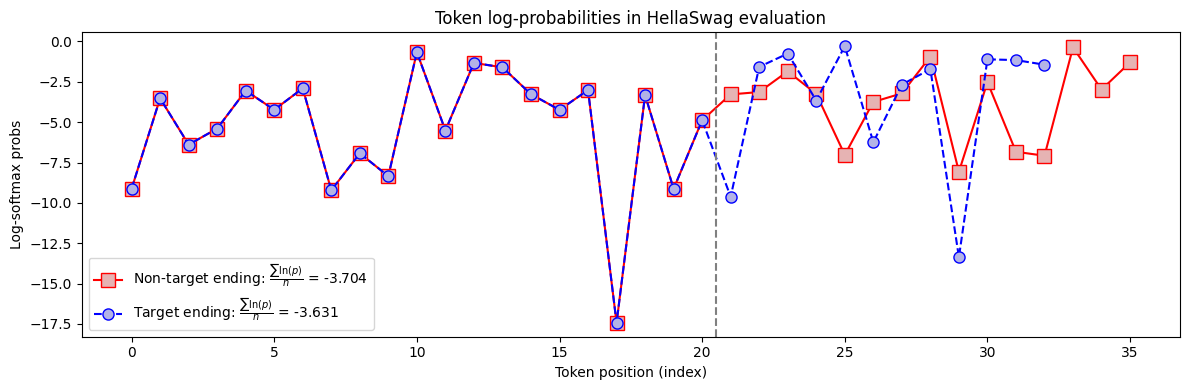

In [63]:
lsmSeqC_np = lsmSeqC.cpu().numpy()
lsmSeqI_np = lsmSeqI.cpu().numpy()
plt.figure(figsize=(12, 4))

# Note the double backslashes \\ and double curly braces {{ }} inside the f-string.
# Matplotlib uses LaTeX for math, and Python f-strings require escaping for backslashes and literal braces.

plt.plot(lsmSeqI_np, 's-', color='r', markersize=10, markerfacecolor=[.9, .7, .7],
         label=f'Non-target ending: $\\frac{{\\sum \\ln(p)}}{{n}}$ = {probI:.3f}')

plt.plot(lsmSeqC_np, 'o--', color='b', markersize=8, markerfacecolor=[.7, .7, .9],
         label=f'Target ending: $\\frac{{\\sum \\ln(p)}}{{n}}$ = {probC:.3f}')

# Vertical line showing where the context ends and the target begins
plt.axvline(context_len - 1.5, linestyle='--', color='gray')

plt.gca().set(xlabel='Token position (index)', ylabel='Log-softmax probs',
              title='Token log-probabilities in HellaSwag evaluation')

plt.legend()
plt.tight_layout()
plt.show()

# Part 4: A function to test one HellaSwag sample

## Task_1:
- Create a function called oneHellaSample that takes a data sample,
model, and tokenizer as input, and implements the following opera
tions.
1. Extract the context, context length in tokens, and target an
swer.
2. Loop over all candidate endings, create the full prompts (that
is, the context and the ending), and store all four prompts as
strings in a list.
3. Tokenize the prompts by inputting the list of prompts into the
tokenizer. Make sure to use padding to account for different
sequence lengths.
4. Runall prompts in one batch. Extract the logits from the model
outputs. If you’re running the models on the GPU, make sure
to move the tokens to the GPU, and the logits back to the CPU.
5. Calculate the log-softmax probabilities from the logits.
6. Calculate the log-likelihoods of each ending. You can copy and
adapt the code from Part 3, but be aware that shorter token
sequences have padding tokens. You’ll need to exclude both
the common context and the padding tokens when calculating
the ending-level log-likelihood. The result of this step will be a
four-element NumPy array that contains the log-likelihood for
each sample ending.
7. Return the log-likelihood array and the index of the target end
ing.
Test your function on one sample to make sure it produces no errors
or warning messages.

In [72]:
tokenizerG.pad_token_id = tokenizerG.eos_token_id
tokenizerG.pad_token_id

50256

In [73]:
texts = [ 'hello',
          'my name is',
          'Mike and I like purple.'
]

t = tokenizerG(texts,padding=True,return_tensors='pt')
for k,v in t.items():
  print(f'"{k}":\n{v}\n')


"input_ids":
tensor([[31373, 50256, 50256, 50256, 50256, 50256],
        [ 1820,  1438,   318, 50256, 50256, 50256],
        [16073,   290,   314,   588, 14032,    13]])

"attention_mask":
tensor([[1, 0, 0, 0, 0, 0],
        [1, 1, 1, 0, 0, 0],
        [1, 1, 1, 1, 1, 1]])



In [75]:
# a function to calculate accuracy on one sample
def oneHellaSample(sample,model,tokenizer):

  # 1) find context length and target
  context = sample['ctx']
  context_len = len( tokenizer.encode(context) )
  target = int(sample['label']) # the target answer

  # 2) loop over candidate endings and create prompts
  allprompts = []
  for opti in range(len(sample['endings'])):
    prompt = f"{context} {sample['endings'][opti]}"
    allprompts.append(prompt)

  # 3) batch tokenize with padding token
  prompt_tox = tokenizer(allprompts,padding=True,return_tensors='pt')

  # 4) run all prompts in one batch and bring the logits back to the CPU
  output = model(**prompt_tox.to(device))
  logits = output.logits.cpu()

  # 5) convert to log probabilities
  log_probs = F.log_softmax(logits,dim=-1)

  # 6) initialize and populate the log-likelihood vector
  loglikelihoods = np.zeros(len(sample['endings']))

  # log-probs for each ending
  for opti in range(len(sample['endings'])):

    # get the token for this ending
    token_seq = prompt_tox['input_ids'][opti].cpu()

    # find the valid (non-pad) tokens
    valid_tox = np.where(token_seq.numpy() != tokenizer.pad_token_id)[0]

    # extract a log-softmax sequence for the valid tokens
    lsmSeq = np.array([ log_probs[opti,i,token_seq[i+1]].item() for i in valid_tox[:-1]])

    # average the valid ending log-probs
    loglikelihoods[opti] = np.mean(lsmSeq[context_len-1:])

  # 7) function outputs
  return loglikelihoods,target


In [76]:
loglikelihoods,target = oneHellaSample(dataset[42],gpt2_s,tokenizerG)

print(f'Log-likelihoods: {loglikelihoods}')
print(f'Target ending: {target}')

if np.argmax(loglikelihoods)==target:
  print('Model was correct!')
else:
  print('Model needs more training ;)')

Log-likelihoods: [-2.94458387 -5.43872503 -3.17445235 -2.28751862]
Target ending: 3
Model was correct!


# Part_5:Test All Four Models

## Task_1:
- Write a for-loop over N data samples. Inside the for-loop, call the
oneHellaSample function four times for the four LLMs you imported
in Part 1. Store the accuracy in a 4×N NumPy array.
If you’re running the analyses on a CPU, set N to be small,
e.g., 50. On a GPU, 1000 samples should take a few minutes.
Create two visualizations of the data. First, a bar plot of av
erage accuracy for the four models, as in Figure 4.28. Second, a
scatter plot of the number of models that got the target for each
sample, as in Figure 4.29. This plot doesn’t show which models
were correct, but it does reveal which data samples are relatively
easy (all four models were correct) vs. difficult (all four models were
incorrect)

In [83]:
# number of data samples to test (set low on CPU!)
num_samples = 1000

# initialize accuracy matrix
accuracies = np.zeros((4,num_samples))


# loop over data samples with progress bar
for datai in tqdm(range(num_samples),desc='Evaluating on HellaSwag'):

  # extract one sample from the data
  example = dataset[datai]

  # test GPT2 small
  loglikelihoods,target = oneHellaSample(example,gpt2_s,tokenizerG)
  if np.argmax(loglikelihoods)==target: accuracies[0,datai] = 1

  # repeat for GPT2-large
  loglikelihoods,target = oneHellaSample(example,gpt2_l,tokenizerG)
  if np.argmax(loglikelihoods)==target: accuracies[1,datai] = 1

  # repeat for roberta-small
  loglikelihoods,target = oneHellaSample(example,roberta_s,tokenizerR)
  if np.argmax(loglikelihoods)==target: accuracies[2,datai] = 1

  # repeat for roberta-large
  loglikelihoods,target = oneHellaSample(example,roberta_l,tokenizerR)
  if np.argmax(loglikelihoods)==target: accuracies[3,datai] = 1

Evaluating on HellaSwag: 100%|██████████| 1000/1000 [12:04<00:00,  1.38it/s]


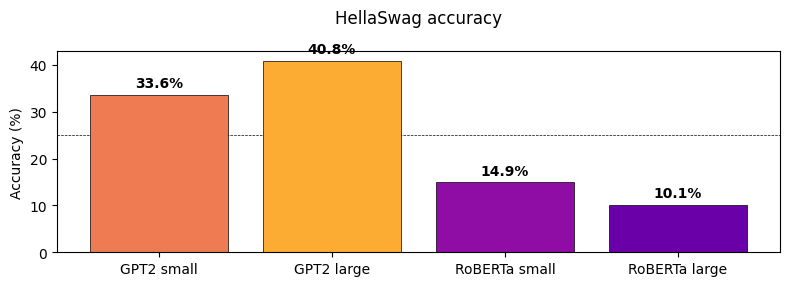

In [84]:
plt.figure(figsize=(8,3))

# draw each bar at a time (for color and text labels)
for i in range(4):

  # accuracy for this model
  acy = 100*accuracies[i,:].mean()

  # the bar
  plt.bar(i,acy,color=plt.cm.plasma(2*acy/100),edgecolor='k',linewidth=.5)

  # write the actual accuracy value
  plt.text(i,1+acy,f'{acy:.1f}%',
           fontweight='bold',ha='center',va='bottom')

# adjust the axies
plt.axhline(25,linestyle='--',color='k',linewidth=.5,zorder=-10)
plt.gca().set(xticks=range(4),xticklabels=['GPT2 small','GPT2 large','RoBERTa small','RoBERTa large'],
              ylabel='Accuracy (%)')
plt.title('HellaSwag accuracy',y=1.1)

plt.tight_layout()
plt.show()


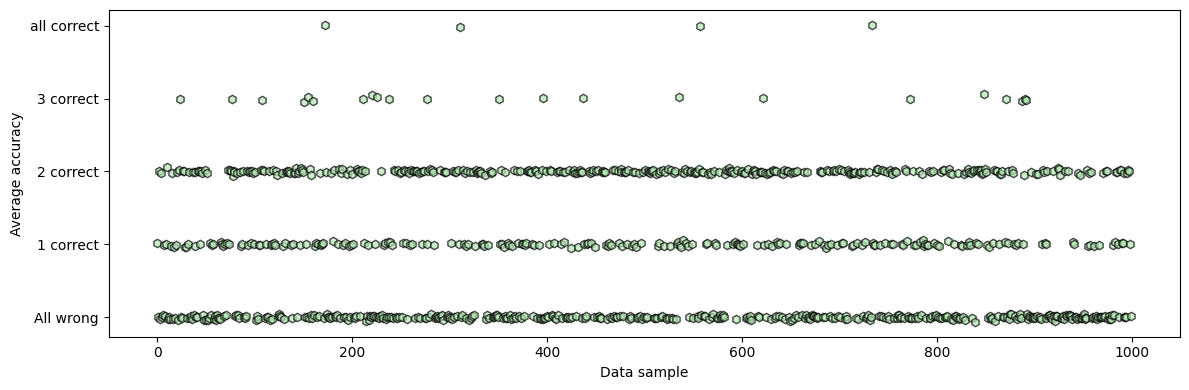

In [85]:
plt.figure(figsize=(12,4))
plt.plot(accuracies.mean(axis=0)+np.random.normal(0,.005,num_samples),'kh',markerfacecolor=[.7,.9,.7,.7])
plt.gca().set(xlabel='Data sample',ylabel='Average accuracy',yticks=np.linspace(0,1,5),
              yticklabels=['All wrong','1 correct','2 correct','3 correct','all correct'])

plt.tight_layout()
plt.show()


# Part_6:Statistical Comparison

## Task_1:
- In a double for-loop over all pairs of models, count the number of
samples where model “A” was incorrect while model “B” was correct,
and put that number into the upper-right element of a 2 × 2 matrix
initialized with zeros. Then count the number of samples where
model “B” was incorrect while model “A” was correct, and put that
number into the lower-left element.
The McNemar test can be run using the mcnemar function in
the contingency_tables module of the statsmodels.stats li
brary. Store the model mean accuracy differences and the McNemar
p-value. Show the results as in Figure 4.30, where the color and
numbers correspond to mean accuracy differences, and the asterisk
indicates that the p-value was less than .05/6 (that’s the significance
threshold with Bonferroni correction for multiple comparisons).